Importing the packages

In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from PIL import Image
import shutil
import random
import pandas as pd
import tensorflow as tf
import keras
import os, time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from keras import layers, models

Spliting the Dataset

In [ ]:

SOURCE_DIRS = [
    Path("archive\seg_test\seg_test"),
    Path("archive\seg_train\seg_train")
]

OUTPUT_DIR = Path("archive/intel_64_split")
IMAGE_SIZE = (64, 64)
SEED = 42

# Collect images from class folders
images = []
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for source in SOURCE_DIRS:
    if not source.exists():
        print("Check missing path:", source)
        continue

    for class_dir in source.iterdir():
        if class_dir.is_dir():
            for path in class_dir.rglob("*"):
                if path.suffix.lower() in extensions:
                    images.append((path, class_dir.name))

if not images:
    raise ValueError(
        "No images found. Check SOURCE_DIRS and folder structure."
    )

# Split into 70% training and 30% temporary
paths = [str(path) for path, label in images]
labels = [label for path, label in images]

train_paths, temp_paths, train_y, temp_y = train_test_split(
    paths, labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Split the remaining 30% equally into validation and test
val_paths, test_paths, val_y, test_y = train_test_split(
    temp_paths, temp_y,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_y
)

splits = {
    "train": (train_paths, train_y),
    "val": (val_paths, val_y),
    "test": (test_paths, test_y)
}

# Resize and save RGB images
for split, (split_paths, split_labels) in splits.items():
    for i, (path, label) in enumerate(zip(split_paths, split_labels)):
        destination = OUTPUT_DIR / split / label / f"{i:06d}.jpg"
        destination.parent.mkdir(parents=True, exist_ok=True)

        try:
            with Image.open(path) as img:
                img.convert("RGB").resize(
                    IMAGE_SIZE, Image.Resampling.LANCZOS
                ).save(destination, quality=95)
        except Exception as e:
            print("Skipped:", path, e)

print("Dataset saved to:", OUTPUT_DIR)
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Praveen\AppData\Local\Temp\ipykernel_12336\1960076233.py:2: SyntaxWarning: invalid escape sequence '\s'
  Path("archive\seg_test\seg_test"),
C:\Users\Praveen\AppData\Local\Temp\ipykernel_12336\1960076233.py:3: SyntaxWarning: invalid escape sequence '\s'
  Path("archive\seg_train\seg_train")


Dataset saved to: archive\intel_64_split
Training images: 11923
Validation images: 2555
Testing images: 2556


In [ ]:
DATA_DIR = Path("archive/intel_64_split")
BATCH = 64
SEED = 42
LOSS = "sparse_categorical_crossentropy"
AUTOTUNE = tf.data.AUTOTUNE

def load(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        DATA_DIR / split, image_size=IMAGE_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=SEED)

raw_train, raw_val, raw_test = load("train", True), load("val", False), load("test", False)
class_names = raw_train.class_names
print(class_names)

# scale pixels to [0,1] (Model A/B have no rescaling layer)
norm = lambda x, y: (tf.cast(x, tf.float32) / 255.0, y)
train_ds = raw_train.map(norm).prefetch(AUTOTUNE)
val_ds   = raw_val.map(norm).prefetch(AUTOTUNE)
test_ds  = raw_test.map(norm).prefetch(AUTOTUNE)

Found 11923 files belonging to 6 classes.
Found 2555 files belonging to 6 classes.
Found 2556 files belonging to 6 classes.
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
NUM_CLASSES= 6
INPUT_SHAPE=(64,64,3)

Defining model A

In [ ]:


#Model A: Standard CNN
def build_model_a():
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        layers.Conv2D(32, (3,3,), padding="same",
                      activation="relu"),

        layers.MaxPooling2D((2,2)),

           layers.Conv2D(64, (3, 3), padding="same",
                      activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same",
                      activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")

    ], name="Model_A_Standard_CNN")

    return model

Defining Model B

In [ ]:
# Model B: Lightweight CNN
def build_model_b():
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        layers.SeparableConv2D(
            32, (3, 3), padding="same",
            activation="relu"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.SeparableConv2D(
            64, (3, 3), padding="same",
            activation="relu"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.SeparableConv2D(
            128, (3, 3), padding="same",
            activation="relu"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="Model_B_Lightweight_CNN")

    return model

In [ ]:
model_a = build_model_a()
model_b = build_model_b()

model_a.summary()
model_b.summary()

print("Model A parameters:", model_a.count_params())
print("Model B parameters:", model_b.count_params())

assert model_b.count_params() <= 100_000

Model: "Model_A_Standard_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,726 (4.36 MB)

 Trainable params: 1,142,726 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d                │ (None, 64, 64, 32)     │           155 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 32, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 16, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,097 (78.50 KB)

 Trainable params: 20,097 (78.50 KB)

 Non-trainable params: 0 (0.00 B)

Model A parameters: 1142726
Model B parameters: 20097


Optimizer Selection

In [ ]:
SELECT_EPOCHS = 15

opt_cfgs = {
    "Adam lr=1e-3":        lambda: keras.optimizers.Adam(learning_rate=1e-3),
    "SGD lr=1e-2":         lambda: keras.optimizers.SGD(learning_rate=1e-2, momentum=0.0),
    "SGD+Mom0.9 lr=1e-2":  lambda: keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9),
}

def run_experiment(build_fn, opt_factory, epochs, tag):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(optimizer=opt_factory(), loss=LOSS, metrics=["accuracy"])
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2)
    print(f"[{tag}] final val_acc={hist.history['val_accuracy'][-1]:.4f}")
    return hist.history

results = {name: run_experiment(build_model_a, f, SELECT_EPOCHS, f"A | {name}")
           for name, f in opt_cfgs.items()}

Epoch 1/15


c:\Users\Praveen\Desktop\CV\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


187/187 - 36s - 193ms/step - accuracy: 0.5947 - loss: 1.0427 - val_accuracy: 0.6845 - val_loss: 0.8438
Epoch 2/15
187/187 - 12s - 63ms/step - accuracy: 0.7362 - loss: 0.7249 - val_accuracy: 0.7444 - val_loss: 0.7014
Epoch 3/15
187/187 - 12s - 64ms/step - accuracy: 0.7764 - loss: 0.6132 - val_accuracy: 0.7796 - val_loss: 0.6151
Epoch 4/15
187/187 - 12s - 65ms/step - accuracy: 0.8157 - loss: 0.5113 - val_accuracy: 0.8035 - val_loss: 0.5626
Epoch 5/15
187/187 - 12s - 64ms/step - accuracy: 0.8385 - loss: 0.4487 - val_accuracy: 0.8039 - val_loss: 0.5551
Epoch 6/15
187/187 - 12s - 64ms/step - accuracy: 0.8631 - loss: 0.3826 - val_accuracy: 0.7933 - val_loss: 0.6017
Epoch 7/15
187/187 - 12s - 64ms/step - accuracy: 0.8846 - loss: 0.3345 - val_accuracy: 0.7988 - val_loss: 0.6034
Epoch 8/15
187/187 - 12s - 63ms/step - accuracy: 0.9093 - loss: 0.2608 - val_accuracy: 0.8184 - val_loss: 0.6184
Epoch 9/15
187/187 - 12s - 63ms/step - accuracy: 0.9259 - loss: 0.2141 - val_accuracy: 0.8090 - val_loss: 

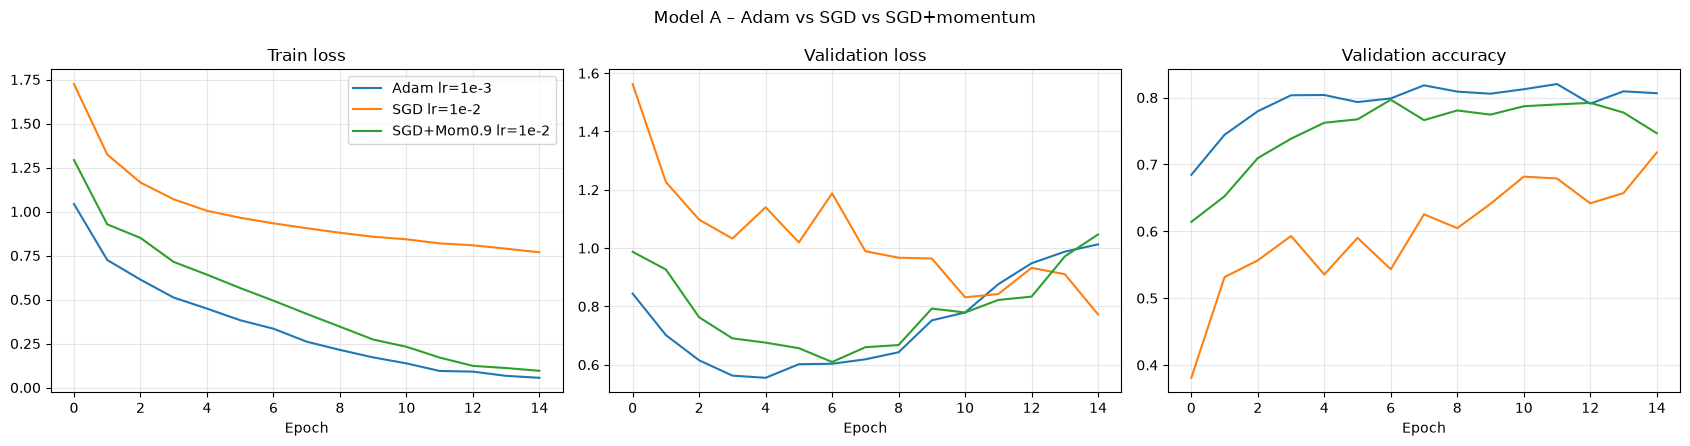

,Optimizer,Best val acc,Final val acc,Final val loss,Epochs to 80% val acc
0,Adam lr=1e-3,0.8204,0.8067,1.0129,4.0
1,SGD lr=1e-2,0.7178,0.7178,0.7724,NaN
2,SGD+Mom0.9 lr=1e-2,0.7969,0.7468,1.0468,NaN


In [ ]:
def plot_runs(results, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    for name, h in results.items():
        ax[0].plot(h["loss"], label=name)
        ax[1].plot(h["val_loss"], label=name)
        ax[2].plot(h["val_accuracy"], label=name)
    for a, t in zip(ax, ["Train loss", "Validation loss", "Validation accuracy"]):
        a.set_title(t); a.set_xlabel("Epoch"); a.grid(alpha=.3)
    ax[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

def summarize(results, thr=0.80):
    rows = []
    for name, h in results.items():
        va = np.array(h["val_accuracy"])
        hit = int(np.argmax(va >= thr)) + 1 if (va >= thr).any() else None
        rows.append({"Optimizer": name, "Best val acc": va.max(),
                     "Final val acc": va[-1], "Final val loss": h["val_loss"][-1],
                     f"Epochs to {int(thr*100)}% val acc": hit})
    return pd.DataFrame(rows).round(4)

plot_runs(results, "Model A – Adam vs SGD vs SGD+momentum")
summarize(results)

Epoch 1/15


c:\Users\Praveen\Desktop\CV\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


187/187 - 12s - 66ms/step - accuracy: 0.2988 - loss: 1.7233 - val_accuracy: 0.3922 - val_loss: 1.5613
Epoch 2/15
187/187 - 12s - 64ms/step - accuracy: 0.4942 - loss: 1.3298 - val_accuracy: 0.4838 - val_loss: 1.3050
Epoch 3/15
187/187 - 12s - 64ms/step - accuracy: 0.5543 - loss: 1.1657 - val_accuracy: 0.5405 - val_loss: 1.1306
Epoch 4/15
187/187 - 12s - 63ms/step - accuracy: 0.5822 - loss: 1.0653 - val_accuracy: 0.6051 - val_loss: 1.0055
Epoch 5/15
187/187 - 12s - 64ms/step - accuracy: 0.6065 - loss: 1.0112 - val_accuracy: 0.6098 - val_loss: 0.9966
Epoch 6/15
187/187 - 12s - 64ms/step - accuracy: 0.6287 - loss: 0.9596 - val_accuracy: 0.6059 - val_loss: 0.9814
Epoch 7/15
187/187 - 12s - 64ms/step - accuracy: 0.6445 - loss: 0.9342 - val_accuracy: 0.6524 - val_loss: 0.9193
Epoch 8/15
187/187 - 11s - 61ms/step - accuracy: 0.6576 - loss: 0.9061 - val_accuracy: 0.6094 - val_loss: 1.0508
Epoch 9/15
187/187 - 12s - 65ms/step - accuracy: 0.6617 - loss: 0.8922 - val_accuracy: 0.6192 - val_loss: 1

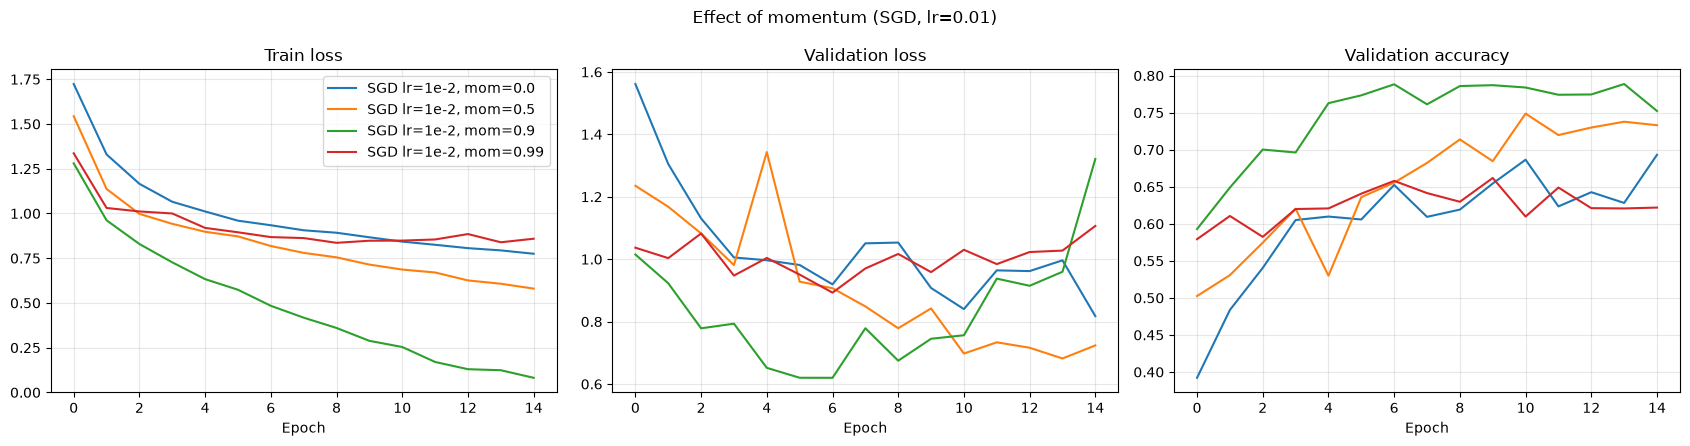

,Optimizer,Best val acc,Final val acc,Final val loss,Epochs to 80% val acc
0,"SGD lr=1e-2, mom=0.0",0.6932,0.6932,0.8175,None
1,"SGD lr=1e-2, mom=0.5",0.7487,0.7331,0.7237,None
2,"SGD lr=1e-2, mom=0.9",0.7886,0.7523,1.3212,None
3,"SGD lr=1e-2, mom=0.99",0.6618,0.6219,1.1066,None


In [ ]:
mom_results = {}
for m in [0.0, 0.5, 0.9, 0.99]:
    mom_results[f"SGD lr=1e-2, mom={m}"] = run_experiment(
        build_model_a,
        lambda m=m: keras.optimizers.SGD(learning_rate=1e-2, momentum=m),
        SELECT_EPOCHS, f"A | mom={m}")

plot_runs(mom_results, "Effect of momentum (SGD, lr=0.01)")
summarize(mom_results)

Training Models and Evaluating

In [ ]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self._t)

def evaluate_model(model, name, hist, times, save_dir="saved_models"):
    os.makedirs(save_dir, exist_ok=True)
    y_true = np.concatenate([y.numpy() for _, y in test_ds])   # test set is not shuffled
    y_pred = model.predict(test_ds, verbose=0).argmax(1)
    path = os.path.join(save_dir, f"{name}.keras")
    model.save(path)
    return {"name": name, "params": model.count_params(),
            "size_kb": os.path.getsize(path) / 1024,
            "sec_per_epoch": float(np.mean(times)),
            "test_acc": float((y_pred == y_true).mean()),
            "y_true": y_true, "y_pred": y_pred, "hist": hist}

def plot_curves(res):
    h = res["hist"]
    plt.figure(figsize=(6, 4))
    plt.plot(h["loss"], label="train"); plt.plot(h["val_loss"], label="validation")
    plt.title(f"{res['name']} – loss"); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.grid(alpha=.3); plt.show()

def report(res):
    print(f"=== {res['name']} | test accuracy = {res['test_acc']:.4f} ===")
    print(classification_report(res["y_true"], res["y_pred"], target_names=class_names, digits=4))
    cm = confusion_matrix(res["y_true"], res["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45, cmap="Blues")
    plt.title(res["name"]); plt.tight_layout(); plt.show()

Epoch 1/25


c:\Users\Praveen\Desktop\CV\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


187/187 - 15s - 78ms/step - accuracy: 0.6097 - loss: 1.0147 - val_accuracy: 0.7159 - val_loss: 0.7588
Epoch 2/25
187/187 - 12s - 66ms/step - accuracy: 0.7465 - loss: 0.7067 - val_accuracy: 0.7609 - val_loss: 0.6562
Epoch 3/25
187/187 - 12s - 65ms/step - accuracy: 0.7902 - loss: 0.5835 - val_accuracy: 0.8012 - val_loss: 0.5548
Epoch 4/25
187/187 - 12s - 67ms/step - accuracy: 0.8268 - loss: 0.4858 - val_accuracy: 0.8059 - val_loss: 0.5383
Epoch 5/25
187/187 - 12s - 65ms/step - accuracy: 0.8527 - loss: 0.4221 - val_accuracy: 0.8082 - val_loss: 0.5225
Epoch 6/25
187/187 - 12s - 64ms/step - accuracy: 0.8713 - loss: 0.3669 - val_accuracy: 0.8086 - val_loss: 0.5912
Epoch 7/25
187/187 - 12s - 64ms/step - accuracy: 0.8915 - loss: 0.3114 - val_accuracy: 0.8067 - val_loss: 0.5811
Epoch 8/25
187/187 - 12s - 63ms/step - accuracy: 0.9067 - loss: 0.2644 - val_accuracy: 0.8192 - val_loss: 0.5940
Epoch 9/25
187/187 - 12s - 63ms/step - accuracy: 0.9301 - loss: 0.2060 - val_accuracy: 0.7926 - val_loss: 0

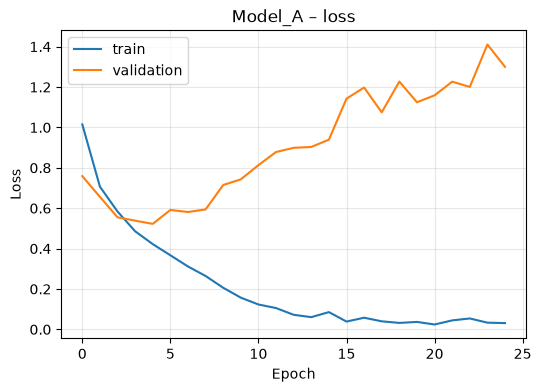

=== Model_A | test accuracy = 0.7821 ===
              precision    recall  f1-score   support

   buildings     0.8323    0.6548    0.7330       394
      forest     0.9580    0.9417    0.9498       412
     glacier     0.8434    0.6306    0.7216       444
    mountain     0.6667    0.7851    0.7210       456
         sea     0.7166    0.8369    0.7721       417
      street     0.7546    0.8453    0.7974       433

    accuracy                         0.7821      2556
   macro avg     0.7953    0.7824    0.7825      2556
weighted avg     0.7929    0.7821    0.7811      2556



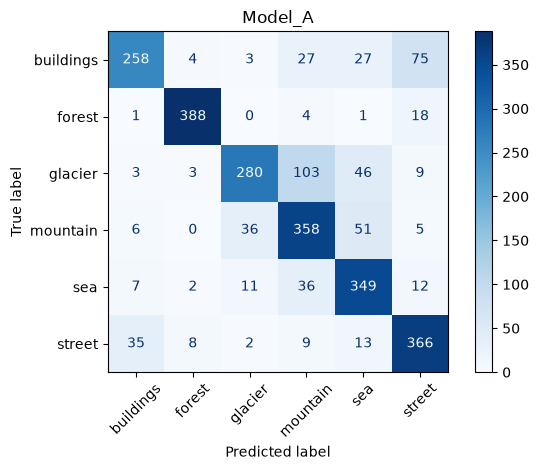

Epoch 1/25


c:\Users\Praveen\Desktop\CV\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


187/187 - 11s - 58ms/step - accuracy: 0.3306 - loss: 1.5582 - val_accuracy: 0.4505 - val_loss: 1.3359
Epoch 2/25
187/187 - 9s - 46ms/step - accuracy: 0.4823 - loss: 1.2799 - val_accuracy: 0.5065 - val_loss: 1.2192
Epoch 3/25
187/187 - 8s - 44ms/step - accuracy: 0.5286 - loss: 1.1861 - val_accuracy: 0.5511 - val_loss: 1.1360
Epoch 4/25
187/187 - 7s - 37ms/step - accuracy: 0.5592 - loss: 1.1241 - val_accuracy: 0.5703 - val_loss: 1.0772
Epoch 5/25
187/187 - 7s - 37ms/step - accuracy: 0.5777 - loss: 1.0728 - val_accuracy: 0.5894 - val_loss: 1.0449
Epoch 6/25
187/187 - 10s - 55ms/step - accuracy: 0.5945 - loss: 1.0334 - val_accuracy: 0.5906 - val_loss: 1.0365
Epoch 7/25
187/187 - 7s - 37ms/step - accuracy: 0.6035 - loss: 1.0051 - val_accuracy: 0.6027 - val_loss: 0.9948
Epoch 8/25
187/187 - 7s - 36ms/step - accuracy: 0.6182 - loss: 0.9744 - val_accuracy: 0.6176 - val_loss: 0.9719
Epoch 9/25
187/187 - 7s - 36ms/step - accuracy: 0.6264 - loss: 0.9541 - val_accuracy: 0.6423 - val_loss: 0.9279
E

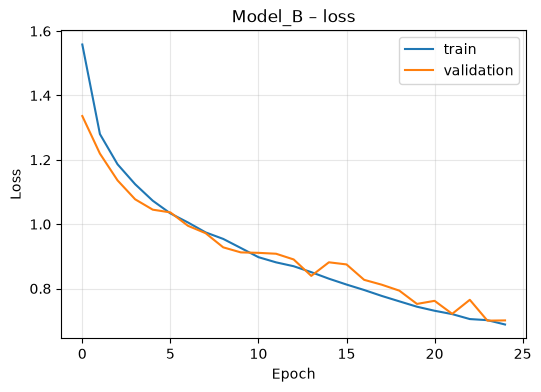

=== Model_B | test accuracy = 0.7308 ===
              precision    recall  f1-score   support

   buildings     0.7079    0.5660    0.6291       394
      forest     0.9582    0.8908    0.9233       412
     glacier     0.7692    0.6982    0.7320       444
    mountain     0.7059    0.6579    0.6810       456
         sea     0.6652    0.7098    0.6868       417
      street     0.6359    0.8591    0.7308       433

    accuracy                         0.7308      2556
   macro avg     0.7404    0.7303    0.7305      2556
weighted avg     0.7394    0.7308    0.7303      2556



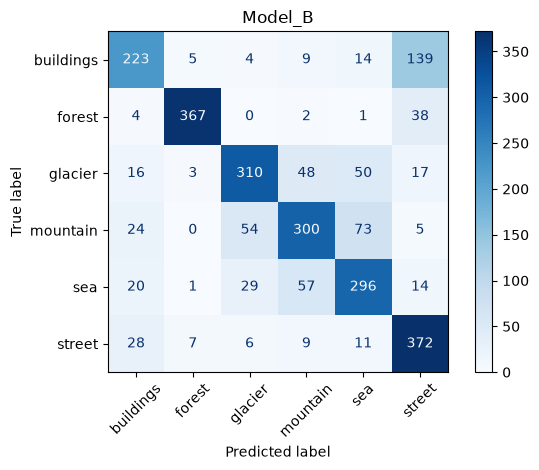

In [ ]:
FINAL_EPOCHS = 25
CHOSEN_OPT = lambda: keras.optimizers.Adam(learning_rate=1e-3)   # <- change per Q3 result

final = {}
for name, builder in [("Model_A", build_model_a), ("Model_B", build_model_b)]:
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    m = builder()
    m.compile(optimizer=CHOSEN_OPT(), loss=LOSS, metrics=["accuracy"])
    timer = EpochTimer()
    hist = m.fit(train_ds, validation_data=val_ds, epochs=FINAL_EPOCHS,
                 callbacks=[timer], verbose=2)
    final[name] = evaluate_model(m, name, hist.history, timer.times)
    plot_curves(final[name]); report(final[name])

In [ ]:
comparison = pd.DataFrame([{
    "Model": k,
    "Total params": r["params"],
    "Size on disk (KB)": round(r["size_kb"], 1),
    "Training time / epoch (s)": round(r["sec_per_epoch"], 2),
    "Test accuracy": round(r["test_acc"], 4)} for k, r in final.items()])
comparison

,Model,Total params,Size on disk (KB),Training time / epoch (s),Test accuracy
0,Model_A,1142726,13435.8,12.74,0.7821
1,Model_B,20097,284.1,7.30,0.7308


In [1]:

import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
Keras: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

!git clone https://github.com/RavPraveen/EN3150_Assignment_03.git

from pathlib import Path

DATA_DIR = Path(
    "/content/EN3150_Assignment_03/archive/intel_64_split"
)

for split in ["train", "val", "test"]:
    folder = DATA_DIR / split

    images = [
        p for p in folder.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    print(f"{split}: {len(images)} images")


Cloning into 'EN3150_Assignment_03'...
remote: Enumerating objects: 17064, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 17064 (delta 4), reused 18 (delta 2), pack-reused 17044 (from 1)
Receiving objects: 100% (17064/17064), 62.27 MiB | 19.98 MiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (17045/17045), done.
train: 11923 images
val: 2555 images
test: 2556 images


In [4]:

import tensorflow as tf
import keras
from pathlib import Path

DATA_DIR = Path(
    "/content/EN3150_Assignment_03/archive/intel_64_split"
)

IMAGE_SIZE = (64, 64)
BATCH = 32
SEED = 42
NUM_CLASSES = 6
AUTOTUNE = tf.data.AUTOTUNE

def load_dataset(split, shuffle=False):
    return keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        image_size=IMAGE_SIZE,
        batch_size=BATCH,
        label_mode="int",
        shuffle=shuffle,
        seed=SEED
    )

raw_train = load_dataset("train", shuffle=True)
raw_val = load_dataset("val", shuffle=False)
raw_test = load_dataset("test", shuffle=False)

class_names = raw_train.class_names

print("\nClass names:", class_names)
print("Number of classes:", len(class_names))
print("Input shape:", IMAGE_SIZE + (3,))


Found 11923 files belonging to 6 classes.
Found 2555 files belonging to 6 classes.
Found 2556 files belonging to 6 classes.

Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6
Input shape: (64, 64, 3)


In [5]:

train_sota = raw_train.prefetch(AUTOTUNE)
val_sota = raw_val.prefetch(AUTOTUNE)
test_sota = raw_test.prefetch(AUTOTUNE)

# Verify image shape, labels, and pixel range
for images, labels in train_sota.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))


Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)
Pixel range: 0.0 255.0


In [6]:

print("GPU devices:", tf.config.list_physical_devices("GPU"))

!nvidia-smi


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mon Oct 19 08:44:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P0             27W /   70W |     111MiB /  15360MiB |      0%      Default |
|                                         |                 

In [7]:

import tensorflow as tf
import keras
from keras import layers

tf.keras.utils.set_random_seed(42)

# Load ImageNet-pretrained MobileNetV2
base_mobilenet = keras.applications.MobileNetV2(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_mobilenet.trainable = False

inputs = keras.Input(shape=(64, 64, 3))

# MobileNetV2 expects pixels scaled to [-1, 1]
x = keras.applications.mobilenet_v2.preprocess_input(inputs)

# Keep BatchNorm in inference mode
x = base_mobilenet(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

mobilenet_model = keras.Model(
    inputs,
    outputs,
    name="MobileNetV2_Intel"
)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

print("\nTotal parameters:",
      mobilenet_model.count_params())


/tmp/ipykernel_949/644232865.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_mobilenet = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Intel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Total parameters: 2422726


In [8]:

head_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history_mobilenet_head = mobilenet_model.fit(
    train_sota,
    validation_data=val_sota,
    epochs=5,
    callbacks=head_callbacks
)


Epoch 1/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.7831 - loss: 0.6039 - val_accuracy: 0.8278 - val_loss: 0.4781
Epoch 2/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8562 - loss: 0.3953 - val_accuracy: 0.8431 - val_loss: 0.4333
Epoch 3/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8823 - loss: 0.3188 - val_accuracy: 0.8431 - val_loss: 0.4411
Epoch 4/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9024 - loss: 0.2588 - val_accuracy: 0.8423 - val_loss: 0.4472
Epoch 5/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9194 - loss: 0.2119 - val_accuracy: 0.8470 - val_loss: 0.4586


In [9]:

base_mobilenet.trainable = True

fine_tune_at = int(len(base_mobilenet.layers) * 0.8)

for i, layer in enumerate(base_mobilenet.layers):
    if i < fine_tune_at:
        layer.trainable = False
    elif isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Total parameters:", mobilenet_model.count_params())
print("Trainable parameters:",
      sum(int(tf.size(w)) for w in mobilenet_model.trainable_weights))

history_mobilenet_fine = mobilenet_model.fit(
    train_sota,
    validation_data=val_sota,
    epochs=15,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)


Total parameters: 2422726
Trainable parameters: 1767622
Epoch 1/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 37s 42ms/step - accuracy: 0.8921 - loss: 0.2910 - val_accuracy: 0.8517 - val_loss: 0.4008
Epoch 2/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9101 - loss: 0.2444 - val_accuracy: 0.8560 - val_loss: 0.4009
Epoch 3/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9210 - loss: 0.2098 - val_accuracy: 0.8626 - val_loss: 0.3929
Epoch 4/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9364 - loss: 0.1766 - val_accuracy: 0.8665 - val_loss: 0.3941
Epoch 5/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9427 - loss: 0.1555 - val_accuracy: 0.8618 - val_loss: 0.3977
Epoch 6/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9524 - loss: 0.1316 - val_accuracy: 0.8665 - val_loss: 0.4029
Epoch 7/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9613 - loss: 0.1135 - val_accuracy: 0.8658 - val_loss: 0.4159
Epoch 8/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 

In [10]:

from sklearn.metrics import classification_report
import numpy as np
import os

test_loss, test_accuracy = mobilenet_model.evaluate(
    test_sota,
    verbose=1
)

y_true = np.concatenate([
    y.numpy() for _, y in test_sota
])

y_prob = mobilenet_model.predict(test_sota)
y_pred = np.argmax(y_prob, axis=1)

print("\nMobileNetV2 Test Accuracy:",
      f"{test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

os.makedirs("/content/saved_models", exist_ok=True)

model_path = "/content/saved_models/mobilenetv2.keras"
mobilenet_model.save(model_path)

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("\nTotal parameters:", mobilenet_model.count_params())
print("Saved model size:", f"{model_size_mb:.2f} MB")


80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.8592 - loss: 0.4143
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step

MobileNetV2 Test Accuracy: 85.92%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.8658    0.8680    0.8669       394
      forest     0.9828    0.9684    0.9756       412
     glacier     0.8362    0.7703    0.8019       444
    mountain     0.7708    0.8333    0.8008       456
         sea     0.8267    0.8465    0.8365       417
      street     0.8920    0.8776    0.8847       433

    accuracy                         0.8592      2556
   macro avg     0.8624    0.8607    0.8611      2556
weighted avg     0.8606    0.8592    0.8594      2556


Total parameters: 2422726
Saved model size: 23.30 MB


In [11]:

import tensorflow as tf
import keras
from keras import layers

keras.utils.set_random_seed(42)

# Load ImageNet-pretrained EfficientNet-B0
base_efficientnet = keras.applications.EfficientNetB0(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained backbone
base_efficientnet.trainable = False

inputs = keras.Input(shape=(64, 64, 3))

# EfficientNet-B0 includes its own input rescaling
# and expects pixel values in [0, 255].
x = base_efficientnet(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_Intel"
)

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

print(
    "\nTotal parameters:",
    efficientnet_model.count_params()
)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Intel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 2, 2, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,313 (16.08 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Total parameters: 4214313


In [12]:

history_efficientnet_head = efficientnet_model.fit(
    train_sota,
    validation_data=val_sota,
    epochs=5,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)


Epoch 1/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 67s 81ms/step - accuracy: 0.8167 - loss: 0.4958 - val_accuracy: 0.8591 - val_loss: 0.3915
Epoch 2/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8630 - loss: 0.3578 - val_accuracy: 0.8701 - val_loss: 0.3742
Epoch 3/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8794 - loss: 0.3173 - val_accuracy: 0.8681 - val_loss: 0.3614
Epoch 4/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8912 - loss: 0.2829 - val_accuracy: 0.8564 - val_loss: 0.3835
Epoch 5/5
373/373 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9025 - loss: 0.2577 - val_accuracy: 0.8673 - val_loss: 0.3755


In [13]:

base_efficientnet.trainable = True

fine_tune_at = int(
    len(base_efficientnet.layers) * 0.8
)

for i, layer in enumerate(base_efficientnet.layers):
    if i < fine_tune_at:
        layer.trainable = False
    elif isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Total parameters:",
    efficientnet_model.count_params()
)

print(
    "Trainable parameters:",
    sum(
        int(tf.size(w))
        for w in efficientnet_model.trainable_weights
    )
)

history_efficientnet_fine = efficientnet_model.fit(
    train_sota,
    validation_data=val_sota,
    epochs=15,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)


Total parameters: 4214313
Trainable parameters: 2452246
Epoch 1/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 57s 74ms/step - accuracy: 0.9022 - loss: 0.2568 - val_accuracy: 0.8724 - val_loss: 0.3553
Epoch 2/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9119 - loss: 0.2318 - val_accuracy: 0.8783 - val_loss: 0.3525
Epoch 3/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9136 - loss: 0.2247 - val_accuracy: 0.8767 - val_loss: 0.3484
Epoch 4/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9218 - loss: 0.2099 - val_accuracy: 0.8795 - val_loss: 0.3464
Epoch 5/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9233 - loss: 0.2067 - val_accuracy: 0.8795 - val_loss: 0.3453
Epoch 6/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9283 - loss: 0.1944 - val_accuracy: 0.8830 - val_loss: 0.3458
Epoch 7/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9310 - loss: 0.1856 - val_accuracy: 0.8810 - val_loss: 0.3436
Epoch 8/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 

In [14]:

from sklearn.metrics import classification_report
import numpy as np
import os

test_loss_eff, test_accuracy_eff = (
    efficientnet_model.evaluate(
        test_sota,
        verbose=1
    )
)

y_true_eff = np.concatenate([
    y.numpy() for _, y in test_sota
])

y_prob_eff = efficientnet_model.predict(test_sota)
y_pred_eff = np.argmax(y_prob_eff, axis=1)

print(
    "\nEfficientNet-B0 Test Accuracy:",
    f"{test_accuracy_eff * 100:.2f}%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_true_eff,
        y_pred_eff,
        target_names=class_names,
        digits=4
    )
)

os.makedirs(
    "/content/saved_models",
    exist_ok=True
)

efficientnet_path = (
    "/content/saved_models/efficientnetb0.keras"
)

efficientnet_model.save(efficientnet_path)

efficientnet_size_mb = (
    os.path.getsize(efficientnet_path) / (1024 ** 2)
)

print(
    "\nTotal parameters:",
    efficientnet_model.count_params()
)

print(
    "Saved model size:",
    f"{efficientnet_size_mb:.2f} MB"
)


80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 148ms/step - accuracy: 0.8830 - loss: 0.3352
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step

EfficientNet-B0 Test Accuracy: 88.30%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.8926    0.8858    0.8892       394
      forest     0.9806    0.9830    0.9818       412
     glacier     0.8146    0.8018    0.8082       444
    mountain     0.8238    0.8202    0.8220       456
         sea     0.8981    0.9305    0.9140       417
      street     0.8974    0.8891    0.8933       433

    accuracy                         0.8830      2556
   macro avg     0.8845    0.8851    0.8847      2556
weighted avg     0.8827    0.8830    0.8828      2556


Total parameters: 4214313
Saved model size: 35.61 MB


In [15]:

from google.colab import drive
import shutil
import os

drive.mount("/content/drive")

destination = (
    "/content/drive/MyDrive/EN3150_Task5_Models"
)

os.makedirs(destination, exist_ok=True)

for filename in [
    "mobilenetv2.keras",
    "efficientnetb0.keras"
]:
    source = f"/content/saved_models/{filename}"

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Saved:", filename)
    else:
        print("Not found:", filename)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: mobilenetv2.keras
Saved: efficientnetb0.keras


In [16]:

from pathlib import Path
import shutil

repo = Path("/content/EN3150_Assignment_03")
model_dir = repo / "saved_models"
model_dir.mkdir(parents=True, exist_ok=True)

for name in ["mobilenetv2.keras", "efficientnetb0.keras"]:
    source = Path("/content/saved_models") / name

    if source.exists():
        shutil.copy2(source, model_dir / name)
        print(f"Copied {name}")
    else:
        print(f"Not found: {name}")


Copied mobilenetv2.keras
Copied efficientnetb0.keras


In [17]:

%cd /content/EN3150_Assignment_03

!git add saved_models/mobilenetv2.keras saved_models/efficientnetb0.keras
!git commit -m "Add fine-tuned MobileNetV2 and EfficientNet-B0 models"


/content/EN3150_Assignment_03
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@224cc6b76b49.(none)')


In [19]:

import json
import zipfile
import shutil
from pathlib import Path
import keras

repo = Path("/content/EN3150_Assignment_03")

model_b_path = repo / "saved_models" / "Model_B.keras"

drive_dir = Path(
    "/content/drive/MyDrive/EN3150_Task5_Models"
)

mobilenet_path = drive_dir / "mobilenetv2.keras"
efficientnet_path = drive_dir / "efficientnetb0.keras"

# Create a compatible copy without modifying the original
fixed_model_b_path = Path("/content/Model_B_compatible.keras")

def remove_unsupported_initializer_args(obj):
    if isinstance(obj, dict):
        if obj.get("class_name") == "GlorotUniform":
            config = obj.get("config", {})
            config.pop("input_axes", None)
            config.pop("output_axes", None)

        for value in obj.values():
            remove_unsupported_initializer_args(value)

    elif isinstance(obj, list):
        for item in obj:
            remove_unsupported_initializer_args(item)

with zipfile.ZipFile(model_b_path, "r") as src:
    with zipfile.ZipFile(fixed_model_b_path, "w") as dst:
        for item in src.infolist():
            content = src.read(item.filename)

            if item.filename == "config.json":
                config = json.loads(content)
                remove_unsupported_initializer_args(config)
                content = json.dumps(config).encode("utf-8")

            dst.writestr(item, content)

print("Compatible copy created:", fixed_model_b_path)

models_task6 = {
    "Model B": keras.models.load_model(
        fixed_model_b_path, compile=False
    ),
    "MobileNetV2": keras.models.load_model(
        mobilenet_path, compile=False
    ),
    "EfficientNet-B0": keras.models.load_model(
        efficientnet_path, compile=False
    )
}

for name, model in models_task6.items():
    print(f"{name}: {model.count_params():,} parameters")


Compatible copy created: /content/Model_B_compatible.keras
Model B: 20,097 parameters
MobileNetV2: 2,422,726 parameters
EfficientNet-B0: 4,214,313 parameters


In [20]:

model_b = models_task6["Model B"]

correct = 0
total = 0

for images, labels in test_sota:
    images = tf.cast(images, tf.float32) / 255.0

    predictions = model_b(images, training=False)
    predicted_labels = tf.argmax(
        predictions, axis=1, output_type=labels.dtype
    )

    correct += int(
        tf.reduce_sum(
            tf.cast(predicted_labels == labels, tf.int32)
        )
    )
    total += int(tf.shape(labels)[0])

accuracy_b = correct / total

print(f"Model B test accuracy: {accuracy_b * 100:.2f}%")
print(f"Test samples: {total}")


Model B test accuracy: 73.08%
Test samples: 2556


In [21]:

import time
import numpy as np
import pandas as pd
import tensorflow as tf

BATCH_SIZE = 32
WARMUP_RUNS = 20
MEASURE_RUNS = 100

rng = np.random.default_rng(42)

input_batch = tf.constant(
    rng.uniform(
        0, 255,
        size=(BATCH_SIZE, 64, 64, 3)
    ).astype("float32")
)

def benchmark_inference(model, normalize=False):
    x = input_batch / 255.0 if normalize else input_batch

    @tf.function
    def infer(batch):
        return model(batch, training=False)

    # Warm up TensorFlow and GPU
    for _ in range(WARMUP_RUNS):
        result = infer(x)
        _ = result.numpy()

    times = []

    for _ in range(MEASURE_RUNS):
        start = time.perf_counter()

        result = infer(x)
        _ = result.numpy()

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return {
        "Batch latency (ms)": np.median(times) * 1000,
        "Time per image (ms)": np.median(times) * 1000 / BATCH_SIZE,
        "Throughput (images/s)": BATCH_SIZE / np.mean(times)
    }

benchmark_results = {}

for name, model in models_task6.items():
    print(f"Benchmarking {name}...")

    benchmark_results[name] = benchmark_inference(
        model,
        normalize=(name == "Model B")
    )

latency_df = pd.DataFrame.from_dict(
    benchmark_results,
    orient="index"
)

display(latency_df.round(3))


Benchmarking Model B...
Benchmarking MobileNetV2...
Benchmarking EfficientNet-B0...


,Batch latency (ms),Time per image (ms),Throughput (images/s)
Model B,3.091,0.097,9365.032
MobileNetV2,13.969,0.437,2063.226
EfficientNet-B0,8.924,0.279,3502.997


In [22]:

import os
import pandas as pd

summary_data = {
    "Model B": {
        "Test accuracy (%)": 73.08,
        "Parameters": 20097,
        "Model size (MB)": os.path.getsize(model_b_path) / (1024 ** 2)
    },
    "MobileNetV2": {
        "Test accuracy (%)": 85.92,
        "Parameters": 2422726,
        "Model size (MB)": os.path.getsize(mobilenet_path) / (1024 ** 2)
    },
    "EfficientNet-B0": {
        "Test accuracy (%)": 88.30,
        "Parameters": 4214313,
        "Model size (MB)": os.path.getsize(efficientnet_path) / (1024 ** 2)
    }
}

comparison_task6 = pd.DataFrame.from_dict(
    summary_data,
    orient="index"
)

comparison_task6 = comparison_task6.join(latency_df)
comparison_task6.index.name = "Model"

display(comparison_task6.round(3))

comparison_task6.to_csv(
    "/content/task6_comparison.csv"
)

print("Comparison saved successfully.")


,Test accuracy (%),Parameters,Model size (MB),Batch latency (ms),Time per image (ms),Throughput (images/s)
Model,,,,,,
Model B,73.08,20097,0.277,3.091,0.097,9365.032
MobileNetV2,85.92,2422726,23.302,13.969,0.437,2063.226
EfficientNet-B0,88.30,4214313,35.612,8.924,0.279,3502.997


Comparison saved successfully.


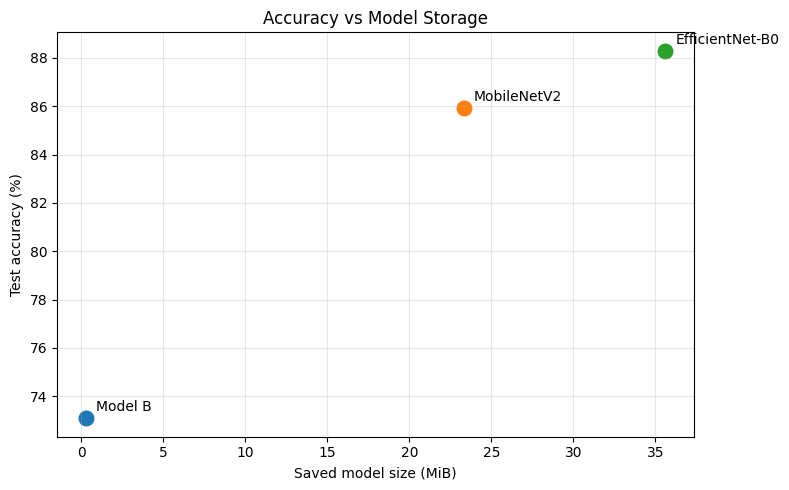

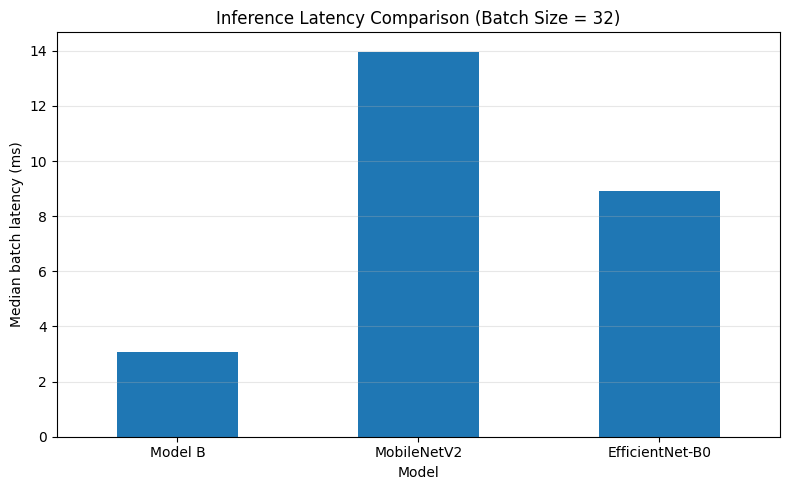

In [23]:

import matplotlib.pyplot as plt

# Accuracy vs saved model size
fig, ax = plt.subplots(figsize=(8, 5))

for name, row in comparison_task6.iterrows():
    ax.scatter(
        row["Model size (MB)"],
        row["Test accuracy (%)"],
        s=110
    )
    ax.annotate(
        name,
        (row["Model size (MB)"], row["Test accuracy (%)"]),
        xytext=(7, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Saved model size (MiB)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Accuracy vs Model Storage")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/task6_accuracy_vs_size.png", dpi=300)
plt.show()

# Compare inference latency
fig, ax = plt.subplots(figsize=(8, 5))

comparison_task6["Batch latency (ms)"].plot.bar(ax=ax)

ax.set_ylabel("Median batch latency (ms)")
ax.set_xlabel("Model")
ax.set_title("Inference Latency Comparison (Batch Size = 32)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/task6_inference_latency.png", dpi=300)
plt.show()


In [24]:

import tensorflow as tf
import pandas as pd

def count_flops(model):
    input_spec = tf.TensorSpec(
        shape=[1, 64, 64, 3],
        dtype=tf.float32
    )

    @tf.function
    def forward(x):
        return model(x, training=False)

    concrete = forward.get_concrete_function(input_spec)

    frozen_func, graph_def = (
        tf.python.framework.convert_to_constants
        .convert_variables_to_constants_v2_as_graph(concrete)
    )

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(
            graph_def, name=""
        )

        options = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

        profile = tf.compat.v1.profiler.profile(
            graph,
            options=options
        )

    return profile.total_float_ops

# More reliable import for Colab
from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2_as_graph
)

def count_flops(model):
    @tf.function
    def forward(x):
        return model(x, training=False)

    concrete = forward.get_concrete_function(
        tf.TensorSpec([1, 64, 64, 3], tf.float32)
    )

    _, graph_def = convert_variables_to_constants_v2_as_graph(
        concrete
    )

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(
            graph_def, name=""
        )

        options = (
            tf.compat.v1.profiler.ProfileOptionBuilder
            .float_operation()
        )

        profile = tf.compat.v1.profiler.profile(
            graph=graph,
            options=options
        )

    return profile.total_float_ops

flops_results = {}

for name, model in models_task6.items():
    print(f"Calculating FLOPs for {name}...")

    flops = count_flops(model)
    flops_results[name] = flops / 1e6

comparison_task6["FLOPs (Millions)"] = (
    pd.Series(flops_results)
)

display(comparison_task6.round(3))


Calculating FLOPs for Model B...


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


Calculating FLOPs for MobileNetV2...
Calculating FLOPs for EfficientNet-B0...


,Test accuracy (%),Parameters,Model size (MB),Batch latency (ms),Time per image (ms),Throughput (images/s),FLOPs (Millions)
Model,,,,,,,
Model B,73.08,20097,0.277,3.091,0.097,9365.032,10.765
MobileNetV2,85.92,2422726,23.302,13.969,0.437,2063.226,50.466
EfficientNet-B0,88.30,4214313,35.612,8.924,0.279,3502.997,66.977


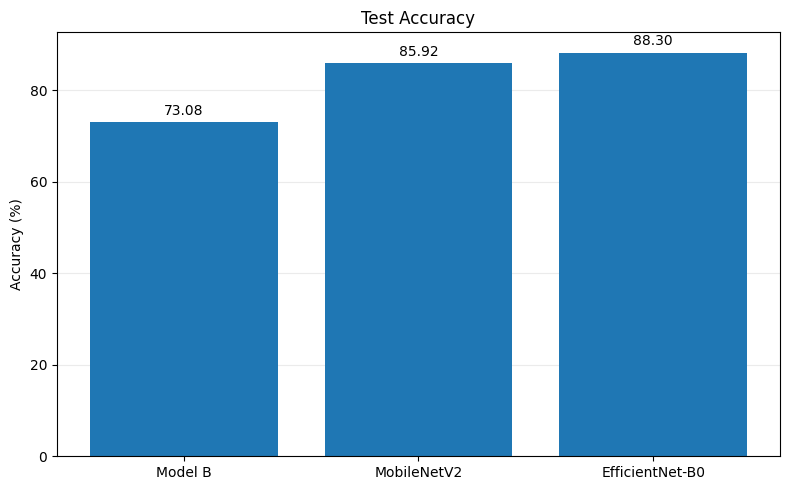

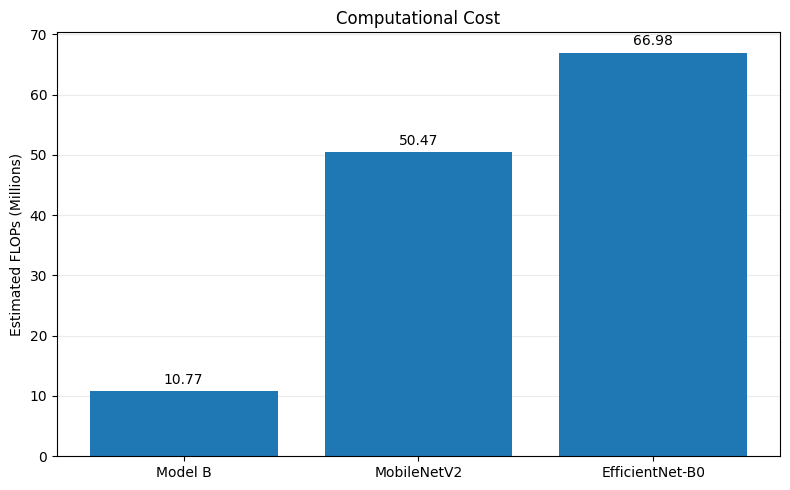

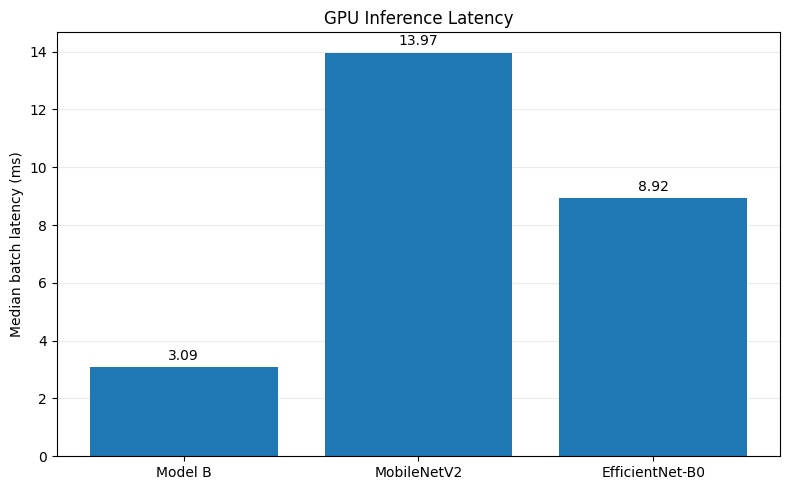

Saved all figures and comparison data.


In [25]:

import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("/content/task6_results")
output_dir.mkdir(parents=True, exist_ok=True)

metrics = [
    ("Test accuracy (%)", "Test Accuracy", "Accuracy (%)"),
    ("FLOPs (Millions)", "Computational Cost", "Estimated FLOPs (Millions)"),
    ("Batch latency (ms)", "GPU Inference Latency", "Median batch latency (ms)")
]

for column, title, ylabel in metrics:
    fig, ax = plt.subplots(figsize=(8, 5))

    bars = ax.bar(
        comparison_task6.index,
        comparison_task6[column]
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    fig.tight_layout()

    filename = column.lower().replace(" ", "_").replace(
        "(", ""
    ).replace(")", "")

    fig.savefig(
        output_dir / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

comparison_task6.to_csv(
    output_dir / "task6_final_comparison.csv"
)

print("Saved all figures and comparison data.")


### Task 6: Accuracy, Memory, and Computational Cost Comparison

The three CNN architectures show a clear trade-off between classification performance and resource requirements. Model B achieved 73.08% test accuracy using only 20,097 parameters, while MobileNetV2 and EfficientNet-B0 achieved 85.92% and 88.30%, respectively.

In terms of computational complexity, Model B required approximately 10.765 million FLOPs per inference, compared with 50.466 million for MobileNetV2 and 66.977 million for EfficientNet-B0. This makes Model B the least computationally demanding architecture among the three. It also had the smallest saved model size, at just 0.277 MiB.

The GPU inference benchmark produced an interesting result. Although EfficientNet-B0 has more parameters and requires more FLOPs than MobileNetV2, it achieved a lower median batch latency of 8.924 ms compared with 13.969 ms for MobileNetV2. This demonstrates that computational complexity does not translate directly into execution time, particularly on GPUs, where operator implementations and hardware utilization can significantly affect performance.

Model B achieved the highest throughput at approximately 9,365 images per second, making it attractive for applications where computational resources are limited. However, this efficiency comes at the cost of classification accuracy. EfficientNet-B0 improved accuracy by 15.22 percentage points over Model B, but required considerably more storage and computation.

Overall, Model B is the preferred architecture when minimizing storage and computational requirements is the primary objective. EfficientNet-B0 is the strongest choice when accuracy is prioritized and sufficient resources are available. MobileNetV2 offers an intermediate accuracy–model-size compromise, although it was slower than EfficientNet-B0 in the measured GPU benchmark.

These results highlight the importance of selecting a CNN architecture according to the intended deployment environment rather than considering classification accuracy alone.

**Experimental limitation:** Inference latency was measured on a Google Colab T4 GPU using batches of 32 images. These measurements do not necessarily reflect single-image latency or performance on embedded hardware. Saved Keras file sizes are storage measurements rather than direct measurements of runtime RAM consumption.

In [26]:

import shutil
from pathlib import Path

repo = Path("/content/EN3150_Assignment_03")
destination = repo / "results" / "task6"
destination.mkdir(parents=True, exist_ok=True)

for file in output_dir.iterdir():
    if file.is_file():
        shutil.copy2(file, destination / file.name)

print("Task 6 results copied to:", destination)
print("Files:")
for file in sorted(destination.iterdir()):
    print("-", file.name)


Task 6 results copied to: /content/EN3150_Assignment_03/results/task6
Files:
- batch_latency_ms.png
- flops_millions.png
- task6_final_comparison.csv
- test_accuracy_%.png


In [27]:

from pathlib import Path

repo = Path("/content/EN3150_Assignment_03")

print("Notebook exists:", (repo / "code.ipynb").exists())

results_dir = repo / "results" / "task6"

print("\nTask 6 results:")
if results_dir.exists():
    for file in sorted(results_dir.iterdir()):
        print("-", file.name)
else:
    print("Results folder not created yet.")


Notebook exists: True

Task 6 results:
- batch_latency_ms.png
- flops_millions.png
- task6_final_comparison.csv
- test_accuracy_%.png


In [28]:

from pathlib import Path
import shutil

repo = Path("/content/EN3150_Assignment_03")
results_dir = repo / "results" / "task6"
results_dir.mkdir(parents=True, exist_ok=True)

# Save the latest comparison data
comparison_task6.to_csv(
    results_dir / "task6_final_comparison.csv"
)

# Copy all generated Task 6 figures
source_dir = Path("/content/task6_results")

if source_dir.exists():
    for file in source_dir.glob("*.png"):
        shutil.copy2(file, results_dir / file.name)

# Include the earlier accuracy/storage and latency plots
for filename in [
    "task6_accuracy_vs_size.png",
    "task6_inference_latency.png"
]:
    source = Path("/content") / filename
    if source.exists():
        shutil.copy2(source, results_dir / filename)

print("Files ready for commit:")
for file in sorted(results_dir.iterdir()):
    print(file.relative_to(repo))


Files ready for commit:
results/task6/batch_latency_ms.png
results/task6/flops_millions.png
results/task6/task6_accuracy_vs_size.png
results/task6/task6_final_comparison.csv
results/task6/task6_inference_latency.png
results/task6/test_accuracy_%.png
